# E60: Do the decomposition's readings and steering order 18 saved fine-tunes by how they were built?

*Re-gating step 2, the table fill. Report: `reports/analyses/2026-10-30_analysis_e60-regating-table.md`. Plan:
`reports/plans/2026-10-30_plan_regating-ground-truth.md`. Results: `experiments/regating_truth_table/results/`.*

## The answer

Yes, on all three task families we have, for both readings that use the decomposition. Each put every fine-tune built
to reuse something the model already does above every fine-tune built to learn something new, with a gap of about half
the scale. Steering keeps the same order. But on the lowercase task its gap shrinks to about a seventh of the scale, and
lowercase read lower than we filed. Reuse here is reuse at the level of the decomposition's pieces. No outside label
exists yet for these runs, so nothing is scored: this is the table a later test will use.

## What we were trying to test

The re-gating line reads from the decomposition whether a fine-tune reuses parts the model already has. Every label it
has been checked against was set by how we built the task. The next step scores it against a label it did not make,
the reuse line's, read on behaviour and an interchange patch with no decomposition. No 67M run has that label yet, so this job fills in the readings first.

**The 18 runs**, two seeds each, all fine-tunes of the same 67M model read through the same decomposition:

- *Copy against random map*, from E46. Each window ends in a rare marker and a key word; the model must say the key's
  value. In copying the value is the key; in a random map it is an arbitrary word. Eight runs.
- *Lowercase against two ciphers*, from E53, on Pile text. Lowercase is a rule the original model already follows. The
  cipher swaps 50 words by a fixed shuffle, the broad cipher 500. Six runs.
- *Elicit map against cipher*, from E54, on marker windows. The elicit map's values are words the original model
  already half-predicts; the cipher's are words it never predicts. Four runs.

Copy and lowercase are **built to reuse**; random maps and ciphers are **built to be new**. The elicit map is **open**:
the model half-knows its answers, so whether the fine-tune reuses that knowledge is the question.

**The three readings.** Each is a share of the fine-tune's gain: 0 when none of the gain is carried, 1 when all of it
is. At the original model the gain is zero and all three are undefined.

- *Gain* $G$: the change in log-odds of the target at the answer position, original model to fine-tuned.
- *Stand-in ratio* $\rho$: write the weight change as the least-squares split. Then $\rho$ is the gain of the
  CI-masked model built from the changed subcomponents, over their gain with no masks. It has no ceiling at 1.
- *Re-gating share* $r = (L_{01} - L_{00}) / G$, with $L$ the CI-masked model on the original subcomponents. Γ's CI
  values come from the fine-tuned model in $L_{01}$ and from the original in $L_{00}$. So $r$ is the share of the gain
  carried by switching on different existing subcomponents.
- *Steering share* $S$, no decomposition. The vector is the mean shift of one block's input at the answer position,
  fine-tuned minus original, over half the windows. Added to the original model, it recovers a share $S$ of the
  fine-tune's gain on the other half, at the best block.

$S$ shares a gain in log probability, while $\rho$ and $r$ share a gain in log-odds, so gap sizes compare only
within a reading. Only $S$ on E53's six runs was missing on disk; every other cell is copied from saved files.

## What we expected, and why

- **Lowercase: steering carries most of the gain**, between 0.4 and 1. Lowercasing the next word is one change shared
  by every window, as copying is, and on copying one vector carried 0.72 to 0.80.
- **Both ciphers: steering carries little**, under 0.35 and 0.3. A word-by-word lookup cannot be one mean vector; on
  the random maps steering read 0.10 to 0.19.
- **Lowercase above both ciphers on steering**, held with high confidence.
- **The ratio and r as already on disk.** The run only collects them.

The tests that need labels were not filed: whether each reading ranks reuse above new, whether it gets the open runs
right, and whether it beats steering. They are filed once the labels exist, before any is read.

## The controls

All passed, first and alone. Every file matched its recorded hash, and a zero weight change gave exactly zero gain.
Three reference runs, one per family, came back identical to their saved readings. The new code path for steering on
text windows matched the split's log-odds gain within 0.0013, against a tolerance of 0.02. That tolerance cites the
wrong source, a path read against itself; the measured floor between these two paths is 0.0025 to 0.005, and the
difference sits under it.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "regating_truth_table"
RUNS = json.loads((EXP / "results" / "table.json").read_text())["runs"]
S0 = json.loads((EXP / "results" / "stage0.json").read_text())["rows"]
# figures: experiments/regating_truth_table/plot.py, from table.json, stage1.json and predictions.json only
print("controls passed:", all(r["ok"] for r in S0.values()), "| runs in the table:", len(RUNS),
      "| every cell defined:", all(c["defined"] for r in RUNS.values() for c in r.values()))

controls passed: True | runs in the table: 18 | every cell defined: True


## Do the readings put every run built to reuse above every run built to be new?

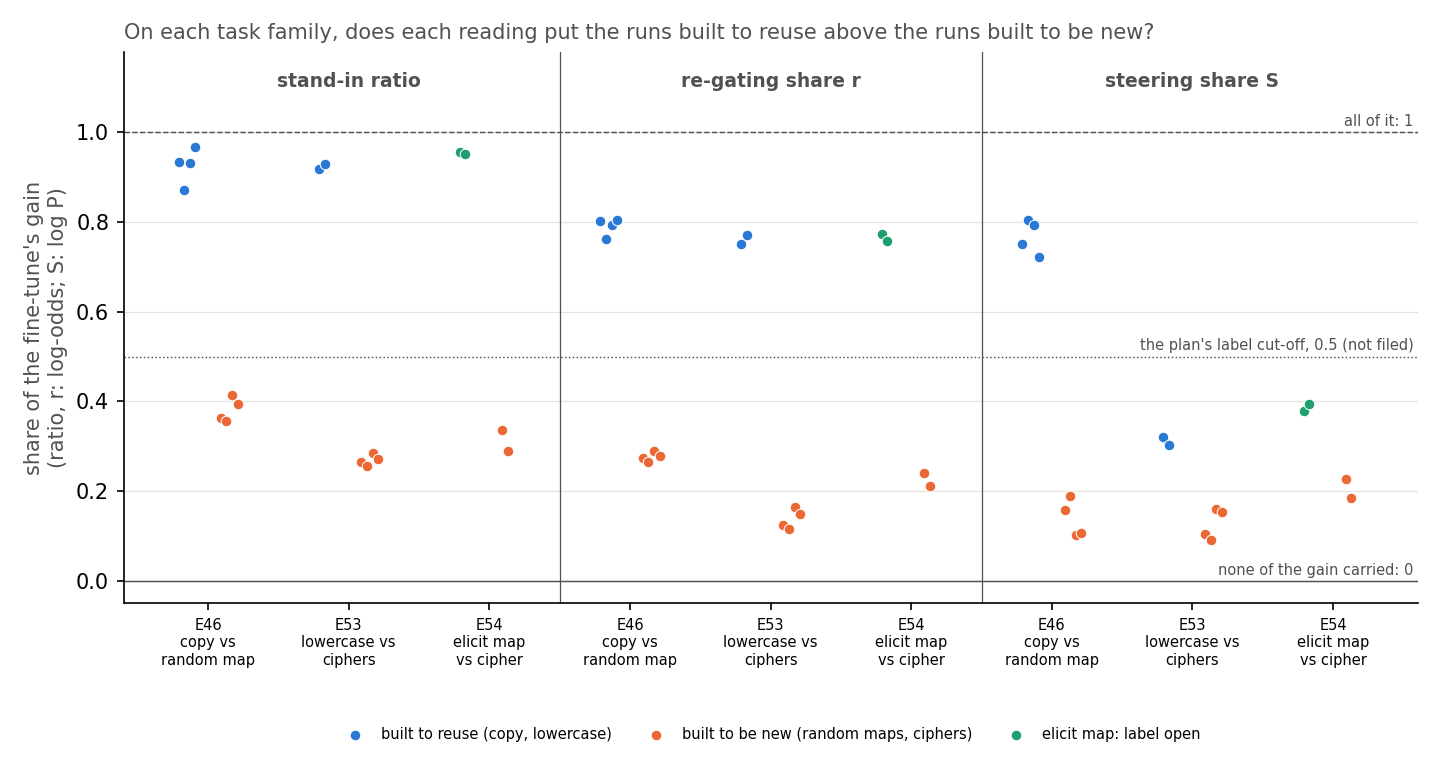

In [2]:
display(Image(EXP / "figures" / "table_shares.png"))

**Reading it.** Yes, for all three readings and on every family. Blue points sit above orange ones in
each of the nine columns. Across families the stand-in ratio reads 0.87 to 0.97 on the runs built to reuse and 0.26
to 0.41 on the runs built to be new. The share r reads 0.75 to 0.80 against 0.12 to 0.29. Steering also orders all
three families. Pooled, its lowest reuse run, lowercase at 0.30, still sits above its highest new run at 0.23. The
dotted line is the plan's cut-off at one half, which is not filed, so what follows is orientation only. Under it the
two decomposition readings would label all 16 built runs as built, while steering would call both lowercase runs new.
On the open elicit map the ratio and r sit with the reuse runs. Steering too ranks it with them: its 0.38 and 0.39
lie above lowercase, inside the reuse runs' range. It reads "new" only under the unfiled cut.

## How far apart are the two kinds, family by family?

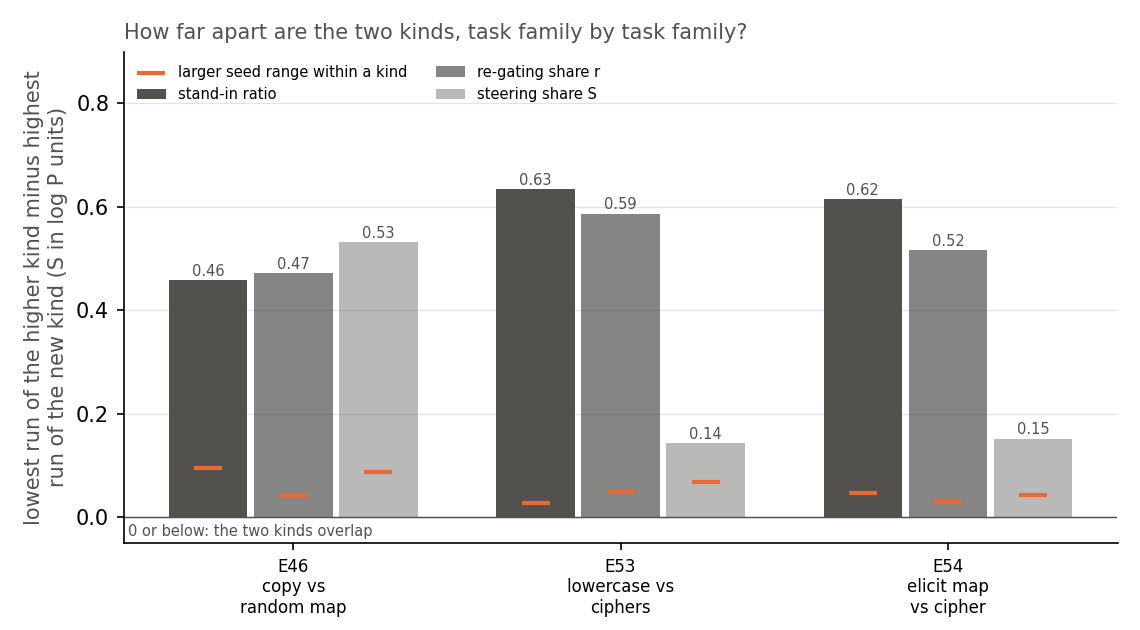

In [3]:
display(Image(EXP / "figures" / "gaps.png"))

**Reading it.** The decomposition's two readings keep a wide gap on every family; steering's gap is
wide on copying only. Each bar is the lowest run of the higher kind minus the highest run of the new kind. For the ratio
and r every bar lies between 0.46 and 0.63. Steering's bar is 0.53 on copy against random map, but 0.14 on lowercase
against the ciphers and 0.15 on the elicit pair. Every bar clears the largest seed spread within a kind, the orange
ticks, which reach 0.10 at most. The caveat is the unit: steering's share is of a log-probability gain, the other two
of a log-odds gain, so steering's bars compare only with each other. The one same-unit comparison is E54's: on the
elicit pair, steering's gap in log-odds is 0.05 against r's 0.54.

## Did steering read where we expected on lowercase?

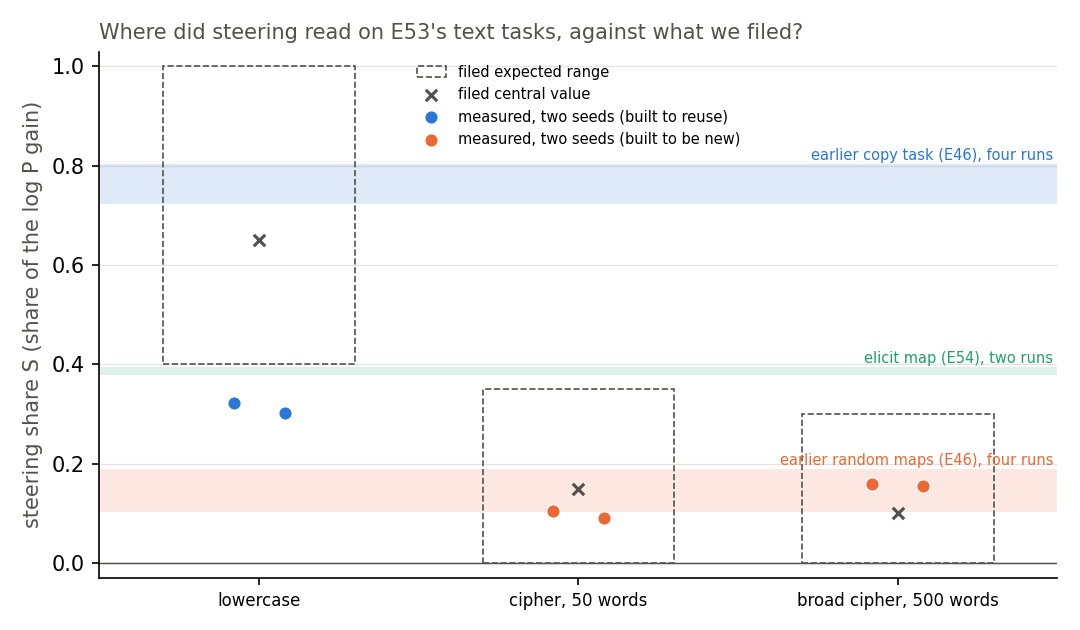

In [4]:
display(Image(EXP / "figures" / "lowercase_S.png"))

**Reading it.** No. Steering carried 0.32 and 0.30 of lowercasing's gain, under the filed range that
starts at 0.4. That is far below copying's band and below the elicit map's. Both ciphers landed inside their
filed ranges, at 0.09 to 0.16, level with the earlier random maps. The filed order held: both lowercase runs sit above
all four cipher runs. So one mean vector moves about a third of lowercasing, not most of it, even though the change is
the same rule for every word. A caveat runs the other way: the fit and scoring halves share documents, which can only
push steering's share up. Both lowercase runs also chose the last block for their vector, as every random map and
cipher did, where every copy and elicit run chose the block before it.

## What we learned

On the 67M model the two decomposition readings now order three task families the same way, and steering's gap
narrows on two of them. For orientation only, under the unfiled cut at one half, lowercase is the first task built to
reuse that steering would call new; the decomposition readings would not. It does not yet show that the readings
track reuse, because every label here but the elicit map's came from how we built the task. Whatever reuse they read
is reuse at the level of VPD's pieces: a new circuit built from old subcomponents would read the same.

## How compelling is the evidence

Two seeds per task, nine tasks, three families. The seed spread within a kind is at most 0.10, under every gap. The
labels are fixed by construction on 16 of the 18 runs, so agreement there was expected. The one open task has two
runs. All three readings are blind to the decomposition's granularity limit: a new circuit made from old subcomponents
reads as reuse.

## Surprises

- Steering on lowercase read 0.30 to 0.32, under the filed range that starts at 0.4. The order against the ciphers
  held. Why one vector carries so little of a rule that is the same for every word is untested.
- The lead asked whether the new path's control should have failed, since its gain in log probability differs from
  the split's gain by 0.08. That difference is the unit. The control compared log-odds with log-odds, as filed.

## What next

- **The open pair**, E58: the elicit map trained on most of its keys and labelled by behaviour on keys it never saw.
  If its runs read "new", the ratio and r disagree with that label, a candidate for the granularity limit. If they read
  "reuses", it is the first outside label the readings get right where steering does not.
- **The reuse line's labels** for these 18 runs, when its Stage B runs. The label tests are filed then, before any
  label is read.
- **Steering in log-odds on E53's six runs**, at no cost. It would put steering's lowercase gap in the same unit as r.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| stage 0 | controls reproduce | hashes, zero gain, three reference runs, new path within 0.02 | all exact; path 1.6721 vs 1.6708 | pass |
| lowercase S | one vector carries most | in [0.4, 1.0], reported only | 0.321, 0.303 | outside, under |
| cipher S | little | in [0, 0.35] | 0.105, 0.091 | inside |
| broad cipher S | little | in [0, 0.3] | 0.159, 0.155 | inside |
| order | lowercase above ciphers | min lowercase > max cipher | 0.303 > 0.159 | as expected |
| P1-P3 | label tests | not filed | no labels exist | not scored |

## Not run

- Any label test: no label exists for a 67M run.
- Steering in log-odds on E53's runs; a random update of matched size as a null for steering.
- Steering with fit and scoring halves drawn from different documents.
- A second decomposition seed; Qwen.

## Departures from the literature

- **Steering departs from contrastive activation addition**, Rimsky et al. 2024. Our vector is the fine-tuned minus
  original mean on the same inputs, added once at the answer position with multiplier 1, read as a share of the
  fine-tune's gain.
- **The fit and scoring halves overlap on E53's windows.** The recipe alternates windows, but E53's windows are in
  document order, so neighbours share documents. That can only push steering's share up; the size is unmeasured.
- **The new path's tolerance cites the wrong source**: a path read against itself, not the measured floor between
  the two log-odds paths. The read difference is under that floor.
- **The route split, the least-squares split, r and the stand-in ratio are this project's own**, not the VPD paper's.

## The full table

In [5]:
KIND = {
 "e46/ident32": "copy, built to reuse",
 "e46/ident32b": "copy, built to reuse",
 "e46/rand32": "random map, built new",
 "e46/rand32b": "random map, built new",
 "e53/lowercase": "lowercase, built to reuse",
 "e53/cipher": "cipher, built new",
 "e53/broad_cipher": "broad cipher, built new",
 "e54/elicit": "elicit map, open",
 "e54/cipher": "cipher, built new"
}
rows = ["| run | kind | stand-in ratio | r | S |", "|---|---|---|---|---|"]
for k, v in RUNS.items():
    task = k.rsplit("_s", 1)[0]
    rows.append(f"| {k} | {KIND[task]} | {v['ratio']['value']:.3f} | {v['r']['value']:.3f} | {v['S']['value']:.3f} |")
display(Markdown("\n".join(rows)))

| run | kind | stand-in ratio | r | S |
|---|---|---|---|---|
| e46/ident32_s0 | copy, built to reuse | 0.934 | 0.802 | 0.750 |
| e46/ident32_s1 | copy, built to reuse | 0.872 | 0.761 | 0.804 |
| e46/ident32b_s0 | copy, built to reuse | 0.931 | 0.792 | 0.794 |
| e46/ident32b_s1 | copy, built to reuse | 0.968 | 0.804 | 0.722 |
| e46/rand32_s0 | random map, built new | 0.364 | 0.273 | 0.158 |
| e46/rand32_s1 | random map, built new | 0.356 | 0.266 | 0.190 |
| e46/rand32b_s0 | random map, built new | 0.414 | 0.290 | 0.103 |
| e46/rand32b_s1 | random map, built new | 0.394 | 0.280 | 0.107 |
| e53/broad_cipher_s0 | broad cipher, built new | 0.285 | 0.165 | 0.159 |
| e53/broad_cipher_s1 | broad cipher, built new | 0.273 | 0.150 | 0.155 |
| e53/cipher_s0 | cipher, built new | 0.264 | 0.124 | 0.105 |
| e53/cipher_s1 | cipher, built new | 0.257 | 0.116 | 0.091 |
| e53/lowercase_s0 | lowercase, built to reuse | 0.919 | 0.752 | 0.321 |
| e53/lowercase_s1 | lowercase, built to reuse | 0.929 | 0.770 | 0.303 |
| e54/cipher_s0 | cipher, built new | 0.336 | 0.241 | 0.228 |
| e54/cipher_s1 | cipher, built new | 0.289 | 0.212 | 0.185 |
| e54/elicit_s0 | elicit map, open | 0.956 | 0.773 | 0.380 |
| e54/elicit_s1 | elicit map, open | 0.951 | 0.758 | 0.394 |

*Provenance.* MATS cluster job 46258, debug QoS, about 90 seconds, peak GPU 22.5 GB, $0. Stage 0
records commit `b4cd9e2`, stage 1 and the table `957501a`: a merge landed mid-job, changing no code this run uses.
Results committed at `d040fb8`. An earlier job, 46252, crashed while loading E53's module and read
nothing; fixed in `1341411`. Figures from `experiments/regating_truth_table/plot.py`.